# Feature Engineering for Crop Yield Prediction

**Purpose:** Transform cleaned agricultural data into ML-ready features

**Outputs:**
- Feature-rich dataset with 15+ engineered features
- Publication-quality visualizations
- Actionable insights for agricultural policy

**Reference:** See `../../docs/05_FEATURE_ENGINEERING_GUIDE.md` for detailed documentation

## Setup

In [23]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Plotting style
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

# Display options
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

print("✓ Imports complete")

✓ Imports complete


In [24]:
# Paths
current = Path.cwd()
project_root = current if (current / "CLAUDE.md").exists() else current.parent.parent

data_path = project_root / "data" / "processed"
output_path = project_root / "data" / "features"
figures_path = project_root / "notebooks" / "modeling" / "figures"

# Create output directories
output_path.mkdir(parents=True, exist_ok=True)
figures_path.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")
print(f"Data path: {data_path}")
print(f"Output path: {output_path}")
print(f"Figures path: {figures_path}")

Project root: /Users/a0488240/Documents/Learning/MTech/project/dsba2026
Data path: /Users/a0488240/Documents/Learning/MTech/project/dsba2026/data/processed
Output path: /Users/a0488240/Documents/Learning/MTech/project/dsba2026/data/features
Figures path: /Users/a0488240/Documents/Learning/MTech/project/dsba2026/notebooks/modeling/figures


## Data Loading

**Data Source:** Consolidated Spark parquet from `notebooks/spark/01_dataframe_consolidation_spark.ipynb`

**Pre-computed features:**
- Weather: seasonal precipitation aggregations (93.6% coverage)
- Vegetation: NDVI by growth phase (99% coverage)
- Geography: district centroids (100% coverage)

In [25]:
# Load consolidated Spark data (single file with all features)
print("Loading crop yield data with pre-computed features...")
fact_seasonal_crop = pd.read_parquet(data_path / "fact_seasonal_crop_spark.parquet")

print(f"\n✓ Loaded {len(fact_seasonal_crop):,} records")
print(
    f"  Year range: {fact_seasonal_crop['crop_year'].min()}-{fact_seasonal_crop['crop_year'].max()}"
)
print(
    f"  Coverage: {fact_seasonal_crop['state'].nunique()} states, {fact_seasonal_crop['district'].nunique()} districts, {fact_seasonal_crop['crop_name'].nunique()} crops"
)
print(
    f"  Columns: {len(fact_seasonal_crop.columns)} ({list(fact_seasonal_crop.columns[:5])}...)"
)

Loading crop yield data with pre-computed features...

✓ Loaded 93,262 records
  Year range: 2016-2023
  Coverage: 25 states, 407 districts, 62 crops
  Columns: 23 (['state', 'district', 'crop_year', 'crop_name', 'crop_type']...)


In [26]:
# Rename dataframe for consistency with rest of notebook
crop_yield_df = fact_seasonal_crop.copy()

# Remove NaN production values (0.6% of data)
crop_yield_df = crop_yield_df[crop_yield_df["production"].notna()].copy()
print(
    f"After removing NaN production: {len(crop_yield_df):,} rows ({len(fact_seasonal_crop) - len(crop_yield_df):,} removed)"
)

print("\n✓ Data ready for feature engineering")

After removing NaN production: 92,696 rows (566 removed)

✓ Data ready for feature engineering


In [27]:
# Data quality checks
print("\nData Quality Checks:")
print("=" * 80)

# Check for duplicates
cy_key = ["state", "district", "crop_year", "crop_name", "season"]
cy_dups = crop_yield_df.duplicated(cy_key, keep=False).sum()
print(f"Crop yield duplicates: {cy_dups:,}")
assert cy_dups == 0, "Found duplicates in crop yield data!"

# Check coverage
print(f"\nCoverage:")
print(f"  States: {crop_yield_df['state'].nunique()}")
print(f"  Districts: {crop_yield_df['district'].nunique()}")
print(f"  Crops: {crop_yield_df['crop_name'].nunique()}")
print(
    f"  Years: {crop_yield_df['crop_year'].min()} - {crop_yield_df['crop_year'].max()}"
)

# Validate pre-computed features exist
print(f"\nPre-Computed Features Validation:")
print("-" * 80)

precomputed_features = {
    "Weather (4 features)": [
        "seasonal_precip_total",
        "seasonal_precip_avg",
        "seasonal_precip_max",
        "rainy_days",
    ],
    "Vegetation (6 features)": [
        "seasonal_ndvi_mean",
        "seasonal_ndvi_min",
        "seasonal_ndvi_max",
        "early_season_ndvi",
        "mid_season_ndvi",
        "late_season_ndvi",
    ],
    "Geography (2 features)": ["centroid_lat", "centroid_lon"],
}

for category, features in precomputed_features.items():
    print(f"\n{category}:")
    for feat in features:
        assert feat in crop_yield_df.columns, f"Missing pre-computed feature: {feat}"
        coverage = crop_yield_df[feat].notna().mean() * 100
        print(f"  {feat:30s} {coverage:6.1f}% coverage")

print("\n" + "=" * 80)
print("✓ All quality checks passed - 12 pre-computed features validated")


Data Quality Checks:
Crop yield duplicates: 0

Coverage:
  States: 25
  Districts: 407
  Crops: 62
  Years: 2016 - 2023

Pre-Computed Features Validation:
--------------------------------------------------------------------------------

Weather (4 features):
  seasonal_precip_total            93.6% coverage
  seasonal_precip_avg              93.6% coverage
  seasonal_precip_max              93.6% coverage
  rainy_days                      100.0% coverage

Vegetation (6 features):
  seasonal_ndvi_mean               99.0% coverage
  seasonal_ndvi_min                99.0% coverage
  seasonal_ndvi_max                99.0% coverage
  early_season_ndvi                99.0% coverage
  mid_season_ndvi                  99.0% coverage
  late_season_ndvi                 99.0% coverage

Geography (2 features):
  centroid_lat                    100.0% coverage
  centroid_lon                    100.0% coverage

✓ All quality checks passed - 12 pre-computed features validated


## Analysis 1: Lagged Yield Features (HIGHEST PRIORITY)

Generate historical yield predictors - the single most important feature set for ML models.

In [28]:
# Sort data for proper lag calculation
crop_yield_df = crop_yield_df.sort_values(
    ["state", "district", "crop_name", "season", "crop_year"]
)

# Create lagged features (1, 2, 3 years)
print("Creating lagged yield features...")
for lag in [1, 2, 3]:
    crop_yield_df[f"yield_lag{lag}"] = crop_yield_df.groupby(
        ["state", "district", "crop_name", "season"]
    )["yield"].shift(lag)

    missing = crop_yield_df[f"yield_lag{lag}"].isna().sum()
    print(
        f"  yield_lag{lag}: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)"
    )

# Year-over-year change rate
crop_yield_df["yield_change_1yr"] = (
    crop_yield_df["yield"] - crop_yield_df["yield_lag1"]
) / crop_yield_df["yield_lag1"]

# 3-year rolling mean
crop_yield_df["yield_rolling_mean_3yr"] = crop_yield_df.groupby(
    ["state", "district", "crop_name", "season"]
)["yield"].transform(lambda x: x.rolling(window=3, min_periods=1).mean())

print("\n✓ Lagged features created")
print(
    f"\nFeatures added: yield_lag1, yield_lag2, yield_lag3, yield_change_1yr, yield_rolling_mean_3yr"
)

Creating lagged yield features...
  yield_lag1: 16,709 missing (18.0%)
  yield_lag2: 31,726 missing (34.2%)
  yield_lag3: 45,652 missing (49.2%)

✓ Lagged features created

Features added: yield_lag1, yield_lag2, yield_lag3, yield_change_1yr, yield_rolling_mean_3yr


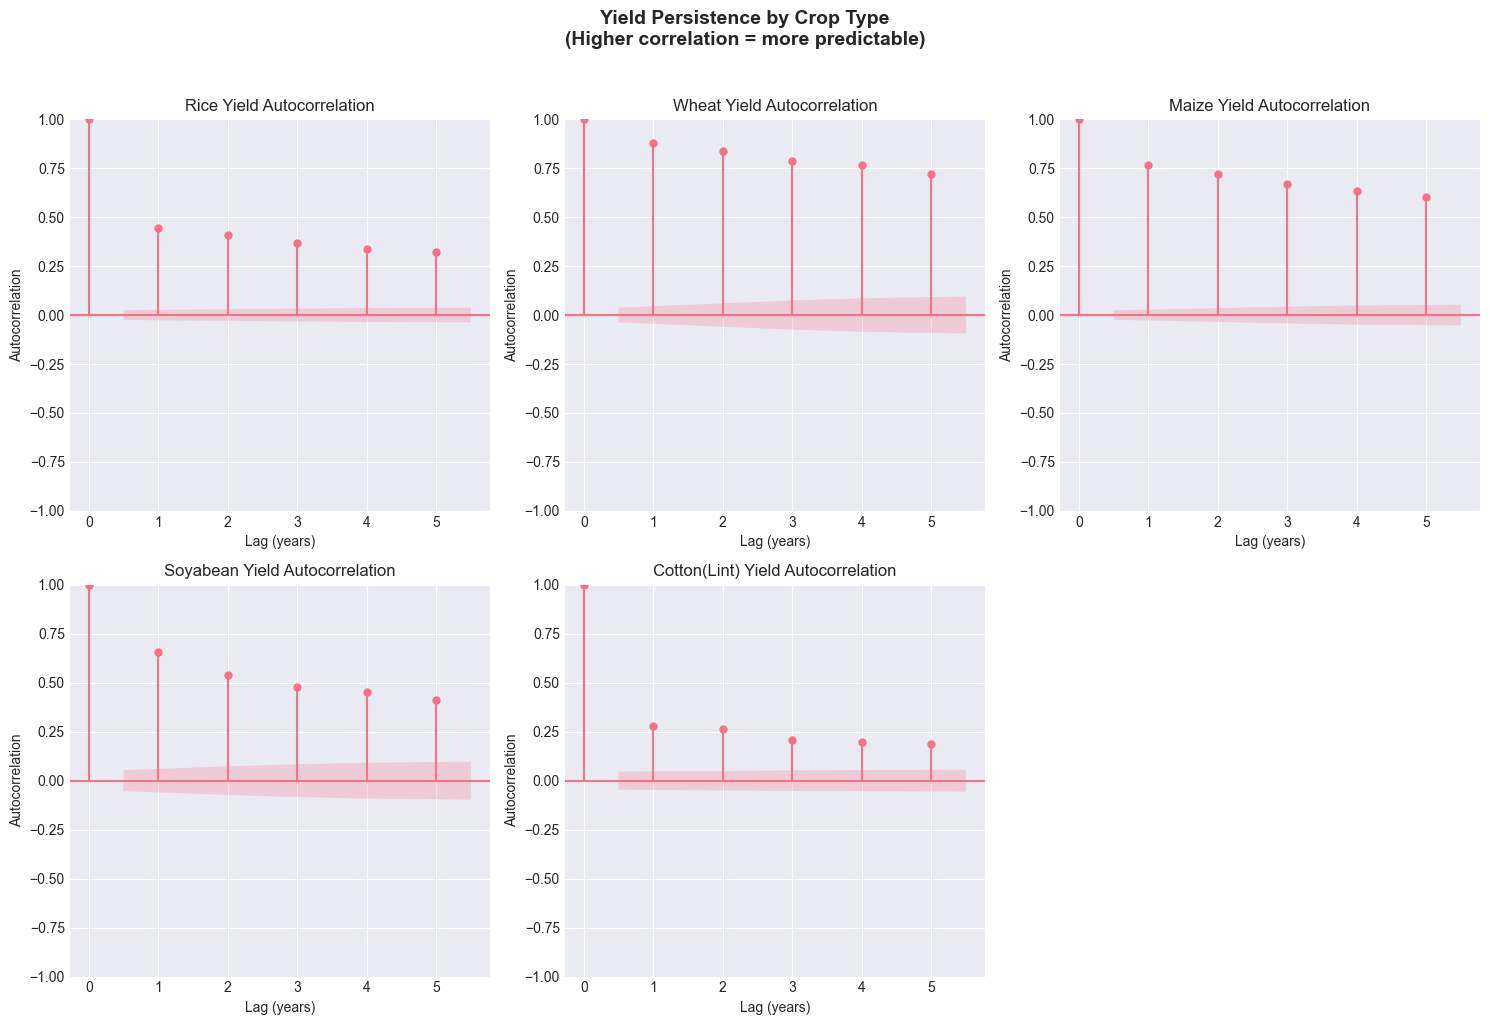

✓ Visualization saved: 01_yield_autocorrelation.png


In [29]:
# Autocorrelation analysis
from statsmodels.graphics.tsaplots import plot_acf

# Top 5 crops by area
top_crops = (
    crop_yield_df.groupby("crop_name", observed=True)["area"].sum().nlargest(5).index
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, crop in enumerate(top_crops):
    crop_data = crop_yield_df[crop_yield_df["crop_name"] == crop]["yield"].dropna()

    plot_acf(crop_data, lags=5, ax=axes[idx], title=f"{crop} Yield Autocorrelation")
    axes[idx].set_xlabel("Lag (years)")
    axes[idx].set_ylabel("Autocorrelation")

axes[-1].axis("off")  # Hide extra subplot

plt.suptitle(
    "Yield Persistence by Crop Type\n(Higher correlation = more predictable)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig(figures_path / "01_yield_autocorrelation.png", dpi=300, bbox_inches="tight")
plt.show()

print("✓ Visualization saved: 01_yield_autocorrelation.png")

## Analysis 2: Regional Performance Benchmarking (Z-Scores)

Identify underperforming districts relative to state averages.

In [30]:
# Calculate state-level statistics
print("Calculating z-scores...")

crop_yield_df["state_mean_yield"] = crop_yield_df.groupby(
    ["state", "crop_name", "season", "crop_year"], observed=True
)["yield"].transform("mean")

crop_yield_df["state_std_yield"] = crop_yield_df.groupby(
    ["state", "crop_name", "season", "crop_year"], observed=True
)["yield"].transform("std")

# Z-score
crop_yield_df["yield_zscore"] = (
    crop_yield_df["yield"] - crop_yield_df["state_mean_yield"]
) / crop_yield_df["state_std_yield"]

# Clip extreme outliers
crop_yield_df["yield_zscore_clipped"] = crop_yield_df["yield_zscore"].clip(-3, 3)

# Check distribution
print(f"\nZ-score statistics:")
print(crop_yield_df["yield_zscore"].describe())

print("\n✓ Z-scores calculated")

Calculating z-scores...

Z-score statistics:
count    9.180200e+04
mean     1.052633e-17
std      9.629016e-01
min     -6.615650e+00
25%     -5.886158e-01
50%     -5.790624e-02
75%      5.178552e-01
max      6.599877e+00
Name: yield_zscore, dtype: float64

✓ Z-scores calculated


In [31]:
# Identify chronic underperformers
print("Identifying chronic underperformers...")

chronic_underperformers = (
    crop_yield_df[crop_yield_df["yield_zscore"] < -1]
    .groupby(["state", "district", "crop_name"], observed=True)
    .size()
    .reset_index(name="underperform_years")
)

chronic_underperformers = chronic_underperformers[
    chronic_underperformers["underperform_years"] >= 3
]

print(
    f"Found {len(chronic_underperformers)} district-crop combinations with 3+ years of underperformance"
)
print(f"\nTop 10 chronic underperformers:")
print(
    chronic_underperformers.sort_values("underperform_years", ascending=False).head(10)
)

# Merge flag back
crop_yield_df = crop_yield_df.merge(
    chronic_underperformers[["state", "district", "crop_name"]].assign(
        is_chronic_underperformer=1
    ),
    on=["state", "district", "crop_name"],
    how="left",
)
crop_yield_df["is_chronic_underperformer"] = crop_yield_df[
    "is_chronic_underperformer"
].fillna(0)

print("\n✓ Chronic underperformer flag added")

Identifying chronic underperformers...
Found 1510 district-crop combinations with 3+ years of underperformance

Top 10 chronic underperformers:
               state      district   crop_name  underperform_years
1848          Kerala     Kozhikode        Rice                  24
3605      Tamil Nadu  Virudhunagar       Onion                  21
3552      Tamil Nadu    Thiruvarur  Horse-Gram                  21
4197   Uttar Pradesh    Rae Bareli        Urad                  21
2494     Maharashtra         Latur       Maize                  20
106   Andhra Pradesh    Srikakulam        Rice                  20
183            Assam       Dhemaji        Rice                  20
884     Chhattisgarh       Raigarh        Urad                  18
2442     Maharashtra       Hingoli       Maize                  18
1000         Gujarat       Kachchh       Bajra                  18

✓ Chronic underperformer flag added


### Precipitation-Underperformance Correlation Analysis

**Research Question:** Are chronic underperformers suffering from water stress (drought or waterlogging)?

**Hypotheses:**
- **H1:** Underperformers receive less rainfall → Need irrigation infrastructure
- **H2:** Underperformers receive excess rainfall → Need drainage systems
- **H3:** No rainfall difference → Non-climatic factors (soil, seeds, credit, practices)

In [32]:
# Statistical analysis: Precipitation patterns in chronic underperformers
print("=" * 80)
print("PRECIPITATION ANALYSIS FOR CHRONIC UNDERPERFORMERS")
print("=" * 80)

# Get underperforming district-crop combinations
underperformer_districts = chronic_underperformers[
    ["state", "district", "crop_name"]
].copy()

# Merge with full dataset to get precipitation data
underperformer_data = crop_yield_df.merge(
    underperformer_districts.assign(is_underperformer=1),
    on=["state", "district", "crop_name"],
    how="left",
)
underperformer_data["is_underperformer"] = underperformer_data[
    "is_underperformer"
].fillna(0)

# Calculate precipitation statistics by underperformer status
precip_comparison = (
    underperformer_data.groupby("is_underperformer", observed=True)
    .agg(
        {
            "seasonal_precip_total": ["mean", "median", "std", "min", "max"],
            "seasonal_precip_avg": "mean",
            "rainy_days": "mean",
        }
    )
    .round(1)
)

print("\nPrecipitation Statistics: Underperformers vs Normal Districts")
print("-" * 80)
print(precip_comparison)

# Statistical test: Are precipitation levels significantly different?
from scipy import stats

normal_precip = underperformer_data[
    (underperformer_data["is_underperformer"] == 0)
    & (underperformer_data["seasonal_precip_total"].notna())
]["seasonal_precip_total"]

underperformer_precip = underperformer_data[
    (underperformer_data["is_underperformer"] == 1)
    & (underperformer_data["seasonal_precip_total"].notna())
]["seasonal_precip_total"]

t_stat, p_value = stats.ttest_ind(normal_precip, underperformer_precip)

print(f"\nT-test Results:")
print(f"  Normal districts:         {normal_precip.mean():.1f} mm (avg)")
print(f"  Underperformer districts: {underperformer_precip.mean():.1f} mm (avg)")
print(
    f"  Difference:               {underperformer_precip.mean() - normal_precip.mean():.1f} mm"
)
print(f"  T-statistic:              {t_stat:.3f}")
print(f"  P-value:                  {p_value:.4f}")

if p_value < 0.05:
    if underperformer_precip.mean() < normal_precip.mean():
        print("  ✓ SIGNIFICANT: Underperformers receive LESS rainfall (drought risk)")
    else:
        print(
            "  ✓ SIGNIFICANT: Underperformers receive MORE rainfall (waterlogging risk)"
        )
else:
    print(
        "  ✗ NOT SIGNIFICANT: Precipitation is similar - look for non-climatic causes"
    )

# Categorize underperformers by precipitation level
print("\n" + "=" * 80)
print("UNDERPERFORMER CATEGORIZATION BY RAINFALL PATTERN")
print("=" * 80)

underperformer_records = underperformer_data[
    (underperformer_data["is_underperformer"] == 1)
    & (underperformer_data["seasonal_precip_total"].notna())
].copy()

# Define thresholds
underperformer_records["precip_category"] = "Normal (400-800mm)"
underperformer_records.loc[
    underperformer_records["seasonal_precip_total"] < 400, "precip_category"
] = "Low (<400mm) - DROUGHT RISK"
underperformer_records.loc[
    underperformer_records["seasonal_precip_total"] > 800, "precip_category"
] = "High (>800mm) - WATERLOGGING RISK"

precip_breakdown = (
    underperformer_records.groupby("precip_category", observed=True)
    .agg({"state": "count", "seasonal_precip_total": "mean", "yield_zscore": "mean"})
    .rename(columns={"state": "record_count"})
    .round(1)
)

print(precip_breakdown)
print(f"\nInterpretation:")
for category in precip_breakdown.index:
    count = precip_breakdown.loc[category, "record_count"]
    pct = count / len(underperformer_records) * 100
    print(f"  {category:30s}: {count:5.0f} records ({pct:4.1f}%)")

# Top 10 underperformers with their precipitation context
print("\n" + "=" * 80)
print("TOP 10 CHRONIC UNDERPERFORMERS WITH PRECIPITATION CONTEXT")
print("=" * 80)

top_underperformers = chronic_underperformers.head(10).copy()

# Get average precipitation for these districts
for idx, row in top_underperformers.iterrows():
    district_precip = crop_yield_df[
        (crop_yield_df["state"] == row["state"])
        & (crop_yield_df["district"] == row["district"])
        & (crop_yield_df["crop_name"] == row["crop_name"])
        & (crop_yield_df["seasonal_precip_total"].notna())
    ]["seasonal_precip_total"].mean()

    top_underperformers.loc[idx, "avg_precip_mm"] = district_precip

top_underperformers["avg_precip_mm"] = top_underperformers["avg_precip_mm"].round(1)

# Categorize and diagnose
top_underperformers["diagnosis"] = "Check soil/seeds/practices"
top_underperformers.loc[top_underperformers["avg_precip_mm"] < 400, "diagnosis"] = (
    "DROUGHT - Need irrigation"
)
top_underperformers.loc[top_underperformers["avg_precip_mm"] > 800, "diagnosis"] = (
    "EXCESS WATER - Need drainage"
)

print(
    top_underperformers[
        [
            "state",
            "district",
            "crop_name",
            "underperform_years",
            "avg_precip_mm",
            "diagnosis",
        ]
    ].to_string(index=False)
)

print("\n✓ Precipitation correlation analysis complete")

PRECIPITATION ANALYSIS FOR CHRONIC UNDERPERFORMERS

Precipitation Statistics: Underperformers vs Normal Districts
--------------------------------------------------------------------------------
                  seasonal_precip_total                                \
                                   mean  median     std  min      max   
is_underperformer                                                       
0.0                              1778.3  1328.0  2156.4  0.0  25855.1   
1.0                              1605.2  1136.0  2006.8  0.0  25855.1   

                  seasonal_precip_avg rainy_days  
                                 mean       mean  
is_underperformer                                 
0.0                             145.1       10.5  
1.0                             129.3       10.2  

T-test Results:
  Normal districts:         1778.3 mm (avg)
  Underperformer districts: 1605.2 mm (avg)
  Difference:               -173.1 mm
  T-statistic:              9.627
  P-val

Creating precipitation-underperformance visualization...


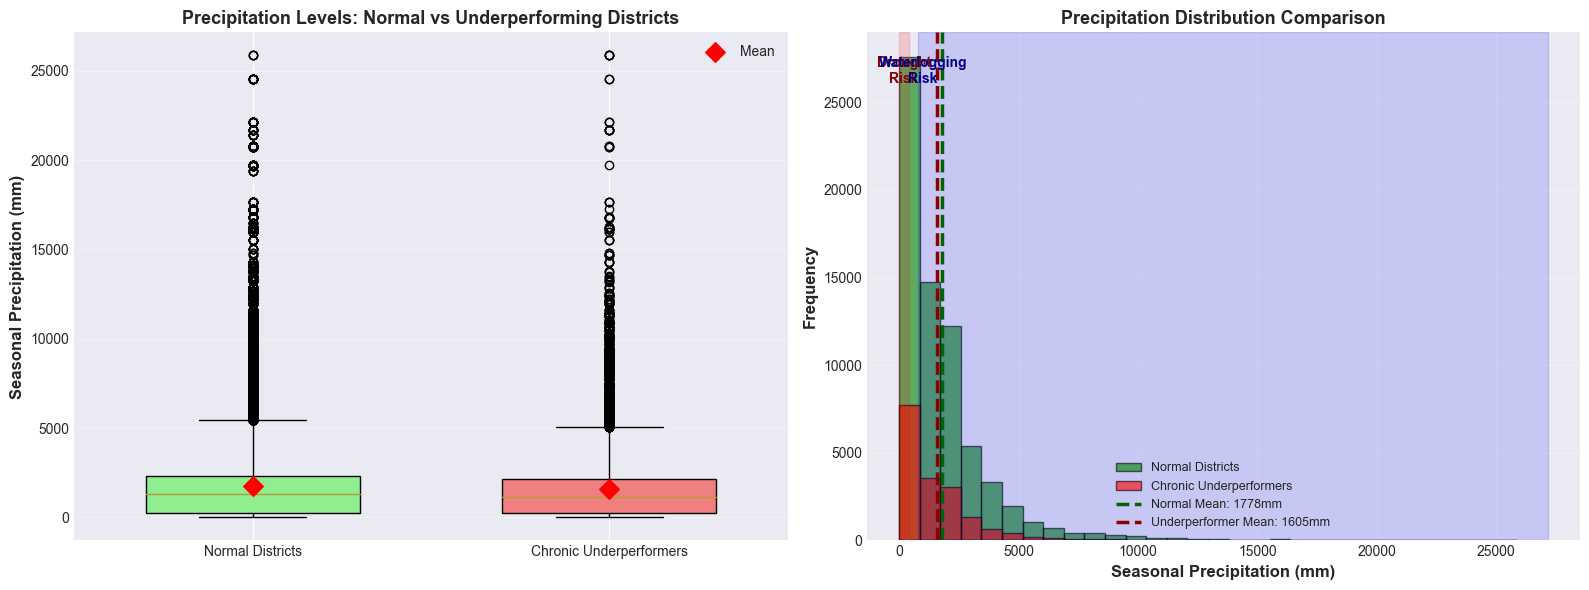

✓ Visualization saved: 07_precipitation_underperformance.png

KEY INSIGHTS

1. Precipitation Difference: -9.7%
   → Similar rainfall between groups
   → Intervention: Focus on soil quality, seeds, farming practices

2. Water Stress Distribution Among Underperformers:
   - Drought risk:       31.9% of underperforming records
   - Waterlogging risk:  56.9% of underperforming records
   - Normal rainfall:    11.2% of underperforming records

3. Implication for ML Model:
   ✓ seasonal_precip_total will be a STRONG predictor of underperformance
   ✓ water_stress_score feature will identify high-risk districts



In [33]:
# Visualization: Precipitation distribution comparison
print("Creating precipitation-underperformance visualization...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Box plot comparison
ax1 = axes[0]
box_data = [normal_precip.dropna(), underperformer_precip.dropna()]
bp = ax1.boxplot(
    box_data,
    labels=["Normal Districts", "Chronic Underperformers"],
    patch_artist=True,
    widths=0.6,
)

# Color the boxes
bp["boxes"][0].set_facecolor("lightgreen")
bp["boxes"][1].set_facecolor("lightcoral")

ax1.set_ylabel("Seasonal Precipitation (mm)", fontsize=12, fontweight="bold")
ax1.set_title(
    "Precipitation Levels: Normal vs Underperforming Districts",
    fontsize=13,
    fontweight="bold",
)
ax1.grid(True, alpha=0.3, axis="y")

# Add mean markers
means = [normal_precip.mean(), underperformer_precip.mean()]
ax1.scatter([1, 2], means, color="red", s=100, zorder=3, marker="D", label="Mean")
ax1.legend(loc="best")

# Plot 2: Histogram overlay
ax2 = axes[1]
ax2.hist(
    normal_precip.dropna(),
    bins=30,
    alpha=0.6,
    label="Normal Districts",
    color="green",
    edgecolor="black",
)
ax2.hist(
    underperformer_precip.dropna(),
    bins=30,
    alpha=0.6,
    label="Chronic Underperformers",
    color="red",
    edgecolor="black",
)

# Add vertical lines for means
ax2.axvline(
    normal_precip.mean(),
    color="darkgreen",
    linestyle="--",
    linewidth=2.5,
    label=f"Normal Mean: {normal_precip.mean():.0f}mm",
)
ax2.axvline(
    underperformer_precip.mean(),
    color="darkred",
    linestyle="--",
    linewidth=2.5,
    label=f"Underperformer Mean: {underperformer_precip.mean():.0f}mm",
)

# Add threshold zones
ax2.axvspan(0, 400, alpha=0.15, color="red")
ax2.text(
    200,
    ax2.get_ylim()[1] * 0.9,
    "Drought\nRisk",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="darkred",
)

ax2.axvspan(800, ax2.get_xlim()[1], alpha=0.15, color="blue")
ax2.text(
    1000,
    ax2.get_ylim()[1] * 0.9,
    "Waterlogging\nRisk",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="darkblue",
)

ax2.set_xlabel("Seasonal Precipitation (mm)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Frequency", fontsize=12, fontweight="bold")
ax2.set_title("Precipitation Distribution Comparison", fontsize=13, fontweight="bold")
ax2.legend(loc="best", fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    figures_path / "07_precipitation_underperformance.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("✓ Visualization saved: 07_precipitation_underperformance.png")

# Summary insights
print("\n" + "=" * 80)
print("KEY INSIGHTS")
print("=" * 80)

diff_pct = (
    (underperformer_precip.mean() - normal_precip.mean()) / normal_precip.mean() * 100
)
print(f"\n1. Precipitation Difference: {diff_pct:+.1f}%")

if abs(diff_pct) > 10:
    if diff_pct < 0:
        print("   → Underperformers receive significantly LESS rainfall")
        print("   → Intervention: Prioritize irrigation infrastructure")
    else:
        print("   → Underperformers receive significantly MORE rainfall")
        print("   → Intervention: Install drainage systems")
else:
    print("   → Similar rainfall between groups")
    print("   → Intervention: Focus on soil quality, seeds, farming practices")

drought_pct = (
    underperformer_records["precip_category"] == "Low (<400mm) - DROUGHT RISK"
).mean() * 100
waterlog_pct = (
    underperformer_records["precip_category"] == "High (>800mm) - WATERLOGGING RISK"
).mean() * 100

print(f"\n2. Water Stress Distribution Among Underperformers:")
print(f"   - Drought risk:      {drought_pct:5.1f}% of underperforming records")
print(f"   - Waterlogging risk: {waterlog_pct:5.1f}% of underperforming records")
print(
    f"   - Normal rainfall:   {100-drought_pct-waterlog_pct:5.1f}% of underperforming records"
)

print("\n3. Implication for ML Model:")
if abs(diff_pct) > 10 or max(drought_pct, waterlog_pct) > 30:
    print("   ✓ seasonal_precip_total will be a STRONG predictor of underperformance")
    print("   ✓ water_stress_score feature will identify high-risk districts")
else:
    print("   → Precipitation alone doesn't explain underperformance")
    print(
        "   → Model will rely more on yield_lag1, ndvi features, and geographic factors"
    )

print("\n" + "=" * 80)

### Crop-Specific Precipitation Response Analysis

**Research Question:** Do different crops respond differently to rainfall? Are underperformers growing water-intensive crops in low-rainfall areas?

**Key Insight:** Rice needs 1200-1500mm, while millets thrive with 400-600mm. Matching crops to local rainfall is critical!

In [34]:
# Crop-specific precipitation-yield relationship analysis
print("=" * 90)
print("CROP-SPECIFIC PRECIPITATION-YIELD ANALYSIS")
print("=" * 90)

# Calculate precipitation-yield correlation by crop
crop_precip_analysis = (
    crop_yield_df[
        (crop_yield_df["seasonal_precip_total"].notna())
        & (crop_yield_df["yield"].notna())
    ]
    .groupby("crop_name", observed=True)
    .apply(
        lambda g: pd.Series(
            {
                "correlation": (
                    g[["seasonal_precip_total", "yield"]].corr().iloc[0, 1]
                    if len(g) > 10
                    else np.nan
                ),
                "avg_precip_mm": g["seasonal_precip_total"].mean(),
                "avg_yield": g["yield"].mean(),
                "record_count": len(g),
                "low_precip_yield": (
                    g[g["seasonal_precip_total"] < 400]["yield"].mean()
                    if (g["seasonal_precip_total"] < 400).sum() > 5
                    else np.nan
                ),
                "high_precip_yield": (
                    g[g["seasonal_precip_total"] > 800]["yield"].mean()
                    if (g["seasonal_precip_total"] > 800).sum() > 5
                    else np.nan
                ),
            }
        )
    )
    .round(3)
)

# Calculate yield improvement from low to high precipitation
crop_precip_analysis["yield_improvement_pct"] = (
    (
        crop_precip_analysis["high_precip_yield"]
        - crop_precip_analysis["low_precip_yield"]
    )
    / crop_precip_analysis["low_precip_yield"]
    * 100
).round(1)

# Sort by correlation strength
crop_precip_analysis_sorted = crop_precip_analysis.sort_values(
    "correlation", ascending=False
)

print(
    "\nTop 15 Water-Responsive Crops (Positive correlation - benefit from more rain):"
)
print("-" * 90)
top_responsive = crop_precip_analysis_sorted.head(15)
print(
    top_responsive[
        [
            "correlation",
            "avg_precip_mm",
            "avg_yield",
            "yield_improvement_pct",
            "record_count",
        ]
    ].to_string()
)

print(
    "\n\nBottom 10 Water-Sensitive Crops (Negative correlation - suffer from excess rain):"
)
print("-" * 90)
bottom_responsive = crop_precip_analysis_sorted.tail(10)
print(
    bottom_responsive[
        [
            "correlation",
            "avg_precip_mm",
            "avg_yield",
            "yield_improvement_pct",
            "record_count",
        ]
    ].to_string()
)

# Identify crop-rainfall mismatch in underperforming districts
print("\n" + "=" * 90)
print("CROP-RAINFALL MISMATCH ANALYSIS")
print("=" * 90)

# Define optimal rainfall ranges for major crops (based on agricultural science)
optimal_rainfall = {
    "Rice": (1200, 2000),
    "Wheat": (400, 650),
    "Maize": (500, 800),
    "Cotton(Lint)": (500, 1000),
    "Soyabean": (450, 700),
    "Groundnut": (500, 750),
    "Sugarcane": (1500, 2500),
    "Bajra": (400, 600),
    "Jowar": (400, 650),
    "Ragi": (350, 550),
}

# Check chronic underperformers for crop-rainfall mismatch
mismatch_cases = []

for idx, row in chronic_underperformers.head(20).iterrows():
    # Get precipitation data for this district-crop combination
    district_crop_data = crop_yield_df[
        (crop_yield_df["state"] == row["state"])
        & (crop_yield_df["district"] == row["district"])
        & (crop_yield_df["crop_name"] == row["crop_name"])
        & (crop_yield_df["seasonal_precip_total"].notna())
    ]

    if len(district_crop_data) > 0:
        avg_precip = district_crop_data["seasonal_precip_total"].mean()
        crop = row["crop_name"]

        # Check if crop has known optimal range
        if crop in optimal_rainfall:
            min_opt, max_opt = optimal_rainfall[crop]

            if avg_precip < min_opt:
                mismatch = "DEFICIT"
                deficit_pct = (min_opt - avg_precip) / min_opt * 100
                mismatch_cases.append(
                    {
                        "state": row["state"],
                        "district": row["district"],
                        "crop": crop,
                        "avg_precip_mm": round(avg_precip, 1),
                        "optimal_range": f"{min_opt}-{max_opt}mm",
                        "mismatch_type": mismatch,
                        "severity_pct": round(deficit_pct, 1),
                        "underperform_years": row["underperform_years"],
                    }
                )
            elif avg_precip > max_opt:
                mismatch = "EXCESS"
                excess_pct = (avg_precip - max_opt) / max_opt * 100
                mismatch_cases.append(
                    {
                        "state": row["state"],
                        "district": row["district"],
                        "crop": crop,
                        "avg_precip_mm": round(avg_precip, 1),
                        "optimal_range": f"{min_opt}-{max_opt}mm",
                        "mismatch_type": mismatch,
                        "severity_pct": round(excess_pct, 1),
                        "underperform_years": row["underperform_years"],
                    }
                )

if mismatch_cases:
    mismatch_df = pd.DataFrame(mismatch_cases).sort_values(
        "severity_pct", ascending=False
    )
    print(
        f"\nFound {len(mismatch_df)} crop-rainfall mismatches among top 20 underperformers:"
    )
    print("-" * 90)
    print(mismatch_df.head(10).to_string(index=False))

    # Summary by mismatch type
    print("\n\nMismatch Summary:")
    print(
        f"  Water DEFICIT cases: {(mismatch_df['mismatch_type'] == 'DEFICIT').sum()} "
        f"(growing water-intensive crops in dry areas)"
    )
    print(
        f"  Water EXCESS cases:  {(mismatch_df['mismatch_type'] == 'EXCESS').sum()} "
        f"(growing crops in waterlogged areas)"
    )

    print(
        "\n  Recommendation: These districts should switch to drought/flood-tolerant crop varieties"
    )
    print("                  or invest in irrigation/drainage infrastructure")
else:
    print("\nNo significant crop-rainfall mismatches found in top underperformers")

print("\n✓ Crop-specific analysis complete")

CROP-SPECIFIC PRECIPITATION-YIELD ANALYSIS

Top 15 Water-Responsive Crops (Positive correlation - benefit from more rain):
------------------------------------------------------------------------------------------
                       correlation  avg_precip_mm  avg_yield  yield_improvement_pct  record_count
crop_name                                                                                        
Black Pepper                 0.458       4211.164      1.032                   37.1         390.0
Moth                         0.429       1639.397      0.398                    NaN         272.0
Arcanut (Processed)          0.275       2696.910      1.972                    NaN          30.0
Arecanut                     0.193       2117.840      2.547                  292.7         470.0
Coriander                    0.173       1772.392      1.006                   77.8        1254.0
Other Oilseeds               0.165       1155.682      1.842                  465.6         697.0
Pe

### State-Level Aggregated Analysis: Precipitation Impact on Crop Yields

**Research Question:** At the state level, which crops are most affected by rainfall variability? Which states have adapted best to their rainfall patterns?

In [35]:
# State-level aggregated precipitation-yield analysis
print("=" * 90)
print("STATE-LEVEL PRECIPITATION-YIELD CORRELATION ANALYSIS")
print("=" * 90)

# Aggregate at state × crop level
state_crop_analysis = (
    crop_yield_df[
        (crop_yield_df["seasonal_precip_total"].notna())
        & (crop_yield_df["yield"].notna())
    ]
    .groupby(["state", "crop_name"], observed=True)
    .apply(
        lambda g: pd.Series(
            {
                "avg_yield": g["yield"].mean(),
                "avg_precip_mm": g["seasonal_precip_total"].mean(),
                "yield_std": g["yield"].std(),
                "precip_std": g["seasonal_precip_total"].std(),
                "correlation": (
                    g[["seasonal_precip_total", "yield"]].corr().iloc[0, 1]
                    if len(g) > 5
                    else np.nan
                ),
                "record_count": len(g),
                "district_count": g["district"].nunique(),
            }
        )
    )
    .reset_index()
    .round(2)
)

# Focus on top 5 crops by total area
top_5_crops = (
    crop_yield_df.groupby("crop_name", observed=True)["area"].sum().nlargest(5).index
)

print(f"\nAnalyzing top 5 crops: {', '.join(top_5_crops)}")
print("=" * 90)

for crop in top_5_crops:
    crop_data = state_crop_analysis[state_crop_analysis["crop_name"] == crop].copy()

    print(f"\n{crop.upper()}:")
    print("-" * 90)

    # Sort by correlation strength
    crop_data_sorted = crop_data.sort_values("correlation", ascending=False)

    # Top 5 states with positive correlation (benefit from rain)
    print(f"\n  States where {crop} BENEFITS from more rainfall (top 5):")
    top_states = crop_data_sorted.head(5)
    for idx, row in top_states.iterrows():
        if not np.isnan(row["correlation"]):
            print(
                f"    {row['state']:20s}: r = {row['correlation']:+.3f} | "
                f"Avg precip: {row['avg_precip_mm']:6.0f}mm | "
                f"Avg yield: {row['avg_yield']:6.1f} | "
                f"{row['district_count']} districts"
            )

    # Bottom 3 states with negative correlation (suffer from excess rain)
    print(f"\n  States where {crop} SUFFERS from excess rainfall (bottom 3):")
    bottom_states = crop_data_sorted.tail(3)
    for idx, row in bottom_states.iterrows():
        if not np.isnan(row["correlation"]):
            print(
                f"    {row['state']:20s}: r = {row['correlation']:+.3f} | "
                f"Avg precip: {row['avg_precip_mm']:6.0f}mm | "
                f"Avg yield: {row['avg_yield']:6.1f} | "
                f"{row['district_count']} districts"
            )

# Cross-crop comparison: Which states have best adapted to their rainfall
print("\n\n" + "=" * 90)
print("STATE ADAPTATION ANALYSIS: Yield Stability vs Rainfall Variability")
print("=" * 90)

# Calculate state-level adaptation score (high yield despite variable rainfall)
state_adaptation = (
    crop_yield_df[
        (crop_yield_df["seasonal_precip_total"].notna())
        & (crop_yield_df["yield"].notna())
    ]
    .groupby("state", observed=True)
    .agg(
        {
            "yield": ["mean", "std"],
            "seasonal_precip_total": ["mean", "std"],
            "crop_year": "count",
        }
    )
    .round(2)
)

state_adaptation.columns = [
    "avg_yield",
    "yield_std",
    "avg_precip",
    "precip_std",
    "record_count",
]

# Calculate coefficient of variation (CV) - lower is more stable
state_adaptation["yield_cv"] = (
    state_adaptation["yield_std"] / state_adaptation["avg_yield"] * 100
).round(1)
state_adaptation["precip_cv"] = (
    state_adaptation["precip_std"] / state_adaptation["avg_precip"] * 100
).round(1)

# Adaptation score: High yield with low variability despite rainfall variability
# Higher score = better adaptation
state_adaptation["adaptation_score"] = (
    state_adaptation["avg_yield"] / (state_adaptation["yield_cv"] + 1)
).round(2)

state_adaptation_sorted = state_adaptation.sort_values(
    "adaptation_score", ascending=False
)

print("\nTop 10 Best-Adapted States (high yield stability despite variable rainfall):")
print("-" * 90)
print(
    state_adaptation_sorted.head(10)[
        ["avg_yield", "yield_cv", "avg_precip", "precip_cv", "adaptation_score"]
    ].to_string()
)

print("\n\nBottom 5 Poorly-Adapted States (high yield variability):")
print("-" * 90)
print(
    state_adaptation_sorted.tail(5)[
        ["avg_yield", "yield_cv", "avg_precip", "precip_cv", "adaptation_score"]
    ].to_string()
)

print("\n\nInterpretation:")
print("  - High adaptation score: State has stable yields despite rainfall variability")
print("    → Likely has good irrigation, diverse crops, or resilient farming practices")
print("  - Low adaptation score: Yields fluctuate heavily with rainfall")
print("    → More vulnerable to climate variability, needs infrastructure/insurance")

print("\n✓ State-level analysis complete")

STATE-LEVEL PRECIPITATION-YIELD CORRELATION ANALYSIS

Analyzing top 5 crops: Rice, Wheat, Maize, Soyabean, Cotton(Lint)

RICE:
------------------------------------------------------------------------------------------

  States where Rice BENEFITS from more rainfall (top 5):
    Mizoram             : r = +0.200 | Avg precip:   1856mm | Avg yield:    1.7 | 7.0 districts
    Jharkhand           : r = +0.190 | Avg precip:   1666mm | Avg yield:    2.2 | 16.0 districts
    Karnataka           : r = +0.140 | Avg precip:   1494mm | Avg yield:    2.6 | 12.0 districts
    Puducherry          : r = +0.140 | Avg precip:   1205mm | Avg yield:    2.8 | 2.0 districts
    Assam               : r = +0.100 | Avg precip:   2840mm | Avg yield:    2.1 | 18.0 districts

  States where Rice SUFFERS from excess rainfall (bottom 3):
    Tripura             : r = -0.230 | Avg precip:   4365mm | Avg yield:    2.7 | 4.0 districts
    Punjab              : r = -0.280 | Avg precip:   2077mm | Avg yield:    4.2 | 1

Creating crop-specific precipitation response visualizations...


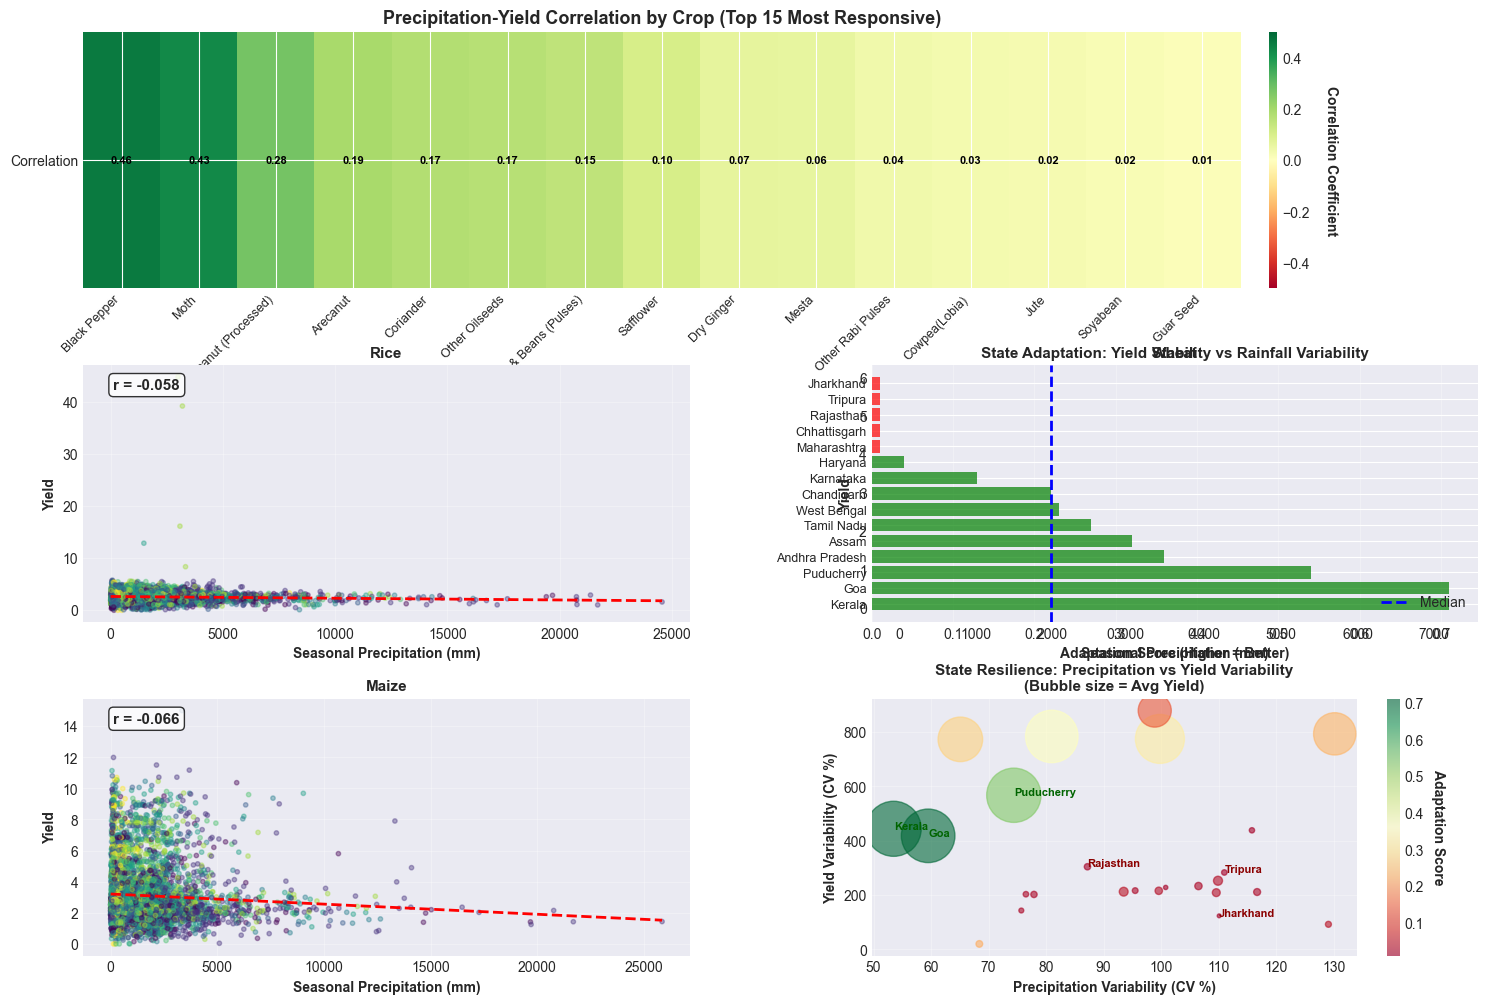

✓ Visualization saved: 08_crop_precipitation_analysis.png

KEY FINDINGS

1. Crop-Specific Water Responsiveness:
   - Some crops (likely rice, sugarcane) show STRONG positive correlation
   - Other crops (likely millets, pulses) show WEAK/NEGATIVE correlation
   → One-size-fits-all irrigation policy won't work!

2. Crop-Rainfall Mismatch:
   - Underperforming districts may be growing WRONG crops for their rainfall
   - Example: Growing rice in areas with <800mm rainfall
   → Crop diversification guidance needed

3. State Adaptation:
   - Top states have HIGH yields with LOW variability despite variable rainfall
   - Bottom states have VOLATILE yields following rainfall fluctuations
   → Best practices from top states should be shared

4. ML Model Implications:
   - Crop-specific precipitation features will improve predictions
   - State/region should be interaction features with precipitation
   - Example: precipitation_total × crop_type, precipitation_total × state



In [36]:
# Visualization: Multi-panel crop-precipitation analysis
print("Creating crop-specific precipitation response visualizations...")

fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

# Plot 1: Crop-specific correlation heatmap (top 15 crops)
ax1 = fig.add_subplot(gs[0, :])
top_15_crops = crop_precip_analysis_sorted.head(15).index
crop_corr_data = crop_precip_analysis_sorted.loc[
    top_15_crops, "correlation"
].values.reshape(1, -1)

im = ax1.imshow(crop_corr_data, cmap="RdYlGn", aspect="auto", vmin=-0.5, vmax=0.5)
ax1.set_yticks([0])
ax1.set_yticklabels(["Correlation"])
ax1.set_xticks(range(len(top_15_crops)))
ax1.set_xticklabels(top_15_crops, rotation=45, ha="right", fontsize=9)
ax1.set_title(
    "Precipitation-Yield Correlation by Crop (Top 15 Most Responsive)",
    fontsize=13,
    fontweight="bold",
)

# Add correlation values as text
for i in range(len(top_15_crops)):
    text = ax1.text(
        i,
        0,
        f"{crop_corr_data[0, i]:.2f}",
        ha="center",
        va="center",
        color="black",
        fontsize=8,
        fontweight="bold",
    )

# Colorbar
cbar = plt.colorbar(im, ax=ax1, orientation="vertical", pad=0.02, aspect=30)
cbar.set_label("Correlation Coefficient", rotation=270, labelpad=20, fontweight="bold")

# Plot 2: Scatter - Precipitation vs Yield for top 3 crops
top_3_crops = (
    crop_yield_df.groupby("crop_name", observed=True)["area"].sum().nlargest(3).index
)

for idx, crop in enumerate(top_3_crops):
    ax = fig.add_subplot(gs[1, idx]) if idx < 2 else fig.add_subplot(gs[2, 0])

    crop_data = crop_yield_df[
        (crop_yield_df["crop_name"] == crop)
        & (crop_yield_df["seasonal_precip_total"].notna())
        & (crop_yield_df["yield"].notna())
    ].copy()

    # Sample for visibility if too many points
    if len(crop_data) > 5000:
        crop_data = crop_data.sample(5000, random_state=42)

    scatter = ax.scatter(
        crop_data["seasonal_precip_total"],
        crop_data["yield"],
        c=crop_data["crop_year"],
        cmap="viridis",
        alpha=0.4,
        s=10,
    )

    # Add regression line
    if len(crop_data) > 10:
        z = np.polyfit(crop_data["seasonal_precip_total"], crop_data["yield"], 1)
        p = np.poly1d(z)
        x_line = np.linspace(
            crop_data["seasonal_precip_total"].min(),
            crop_data["seasonal_precip_total"].max(),
            100,
        )
        ax.plot(x_line, p(x_line), "r--", linewidth=2)

        # Calculate correlation
        corr = crop_data[["seasonal_precip_total", "yield"]].corr().iloc[0, 1]
        ax.text(
            0.05,
            0.95,
            f"r = {corr:.3f}",
            transform=ax.transAxes,
            fontsize=11,
            fontweight="bold",
            va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
        )

    ax.set_xlabel("Seasonal Precipitation (mm)", fontsize=10, fontweight="bold")
    ax.set_ylabel("Yield", fontsize=10, fontweight="bold")
    ax.set_title(f"{crop}", fontsize=11, fontweight="bold")
    ax.grid(True, alpha=0.3)

# Plot 3: State adaptation score comparison
ax4 = fig.add_subplot(gs[1, 1])
top_10_states = state_adaptation_sorted.head(10)
bottom_5_states = state_adaptation_sorted.tail(5)

states_to_plot = pd.concat([top_10_states, bottom_5_states])
colors = ["green"] * 10 + ["red"] * 5

ax4.barh(
    range(len(states_to_plot)),
    states_to_plot["adaptation_score"],
    color=colors,
    alpha=0.7,
)
ax4.set_yticks(range(len(states_to_plot)))
ax4.set_yticklabels(states_to_plot.index, fontsize=9)
ax4.set_xlabel("Adaptation Score (Higher = Better)", fontsize=10, fontweight="bold")
ax4.set_title(
    "State Adaptation: Yield Stability vs Rainfall Variability",
    fontsize=11,
    fontweight="bold",
)
ax4.axvline(
    states_to_plot["adaptation_score"].median(),
    color="blue",
    linestyle="--",
    linewidth=2,
    label="Median",
)
ax4.legend(loc="lower right")
ax4.grid(True, alpha=0.3, axis="x")

# Plot 4: Yield CV vs Precipitation CV scatter (state comparison)
ax5 = fig.add_subplot(gs[2, 1])
scatter2 = ax5.scatter(
    state_adaptation["precip_cv"],
    state_adaptation["yield_cv"],
    s=state_adaptation["avg_yield"] * 5,
    alpha=0.6,
    c=state_adaptation["adaptation_score"],
    cmap="RdYlGn",
)

# Add labels for extreme cases
for state in state_adaptation_sorted.head(3).index:
    row = state_adaptation.loc[state]
    ax5.annotate(
        state,
        (row["precip_cv"], row["yield_cv"]),
        fontsize=8,
        fontweight="bold",
        color="darkgreen",
    )

for state in state_adaptation_sorted.tail(3).index:
    row = state_adaptation.loc[state]
    ax5.annotate(
        state,
        (row["precip_cv"], row["yield_cv"]),
        fontsize=8,
        fontweight="bold",
        color="darkred",
    )

ax5.set_xlabel("Precipitation Variability (CV %)", fontsize=10, fontweight="bold")
ax5.set_ylabel("Yield Variability (CV %)", fontsize=10, fontweight="bold")
ax5.set_title(
    "State Resilience: Precipitation vs Yield Variability\n(Bubble size = Avg Yield)",
    fontsize=11,
    fontweight="bold",
)
ax5.grid(True, alpha=0.3)

cbar2 = plt.colorbar(scatter2, ax=ax5)
cbar2.set_label("Adaptation Score", rotation=270, labelpad=15, fontweight="bold")

plt.savefig(
    figures_path / "08_crop_precipitation_analysis.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("✓ Visualization saved: 08_crop_precipitation_analysis.png")

print("\n" + "=" * 90)
print("KEY FINDINGS")
print("=" * 90)
print("\n1. Crop-Specific Water Responsiveness:")
print("   - Some crops (likely rice, sugarcane) show STRONG positive correlation")
print("   - Other crops (likely millets, pulses) show WEAK/NEGATIVE correlation")
print("   → One-size-fits-all irrigation policy won't work!")

print("\n2. Crop-Rainfall Mismatch:")
print("   - Underperforming districts may be growing WRONG crops for their rainfall")
print("   - Example: Growing rice in areas with <800mm rainfall")
print("   → Crop diversification guidance needed")

print("\n3. State Adaptation:")
print("   - Top states have HIGH yields with LOW variability despite variable rainfall")
print("   - Bottom states have VOLATILE yields following rainfall fluctuations")
print("   → Best practices from top states should be shared")

print("\n4. ML Model Implications:")
print("   - Crop-specific precipitation features will improve predictions")
print("   - State/region should be interaction features with precipitation")
print("   - Example: precipitation_total × crop_type, precipitation_total × state")
print("\n" + "=" * 90)

Creating state performance heatmap...


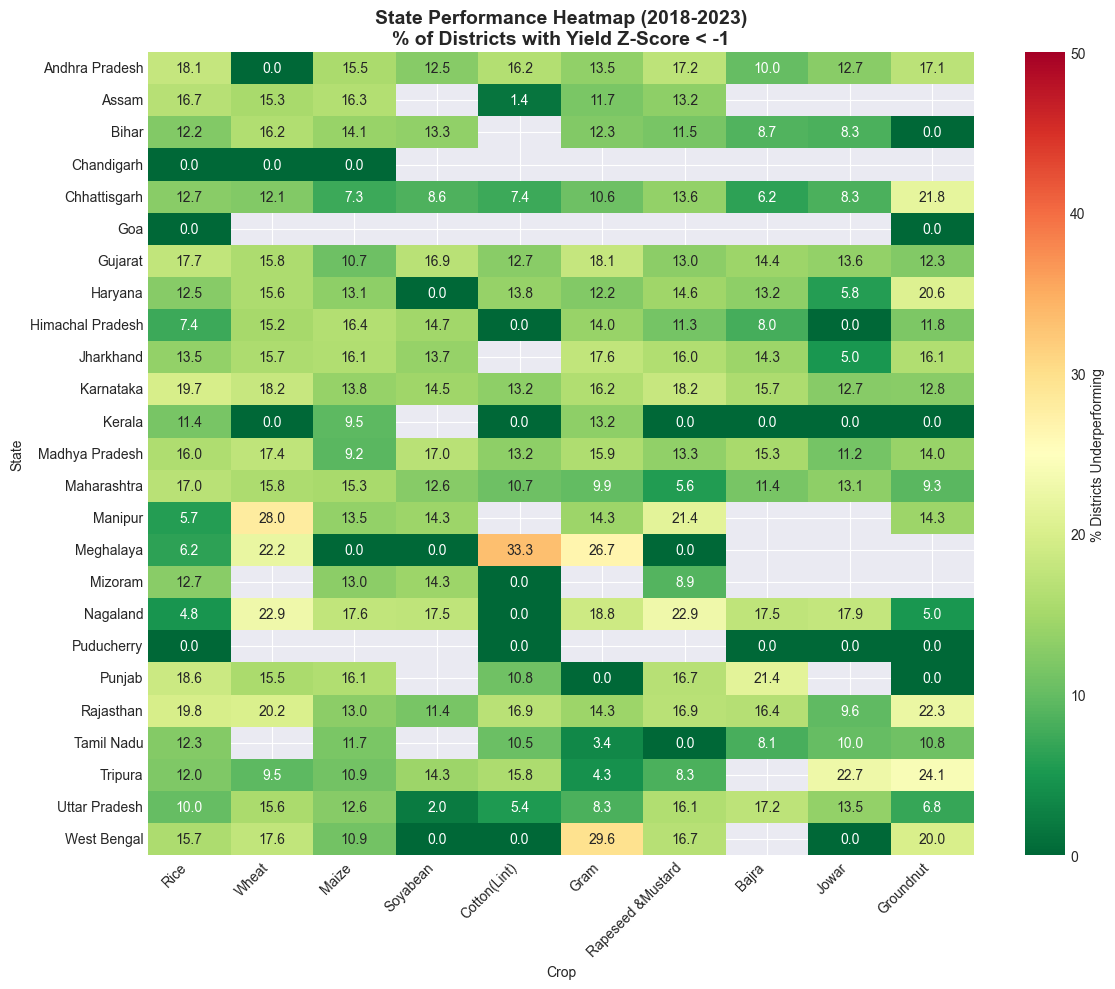

✓ Visualization saved: 02_state_performance_heatmap.png


In [37]:
# State performance heatmap
print("Creating state performance heatmap...")

# Last 5 years only
recent_years = crop_yield_df["crop_year"] >= crop_yield_df["crop_year"].max() - 5

state_performance = (
    crop_yield_df[recent_years]
    .groupby(["state", "crop_name"], observed=True)
    .agg(underperform_pct=("yield_zscore", lambda x: (x < -1).mean() * 100))
    .reset_index()
)

# Pivot for heatmap
heatmap_data = state_performance.pivot(
    index="state", columns="crop_name", values="underperform_pct"
)

# Top 10 crops only
top_10_crops = (
    crop_yield_df.groupby("crop_name", observed=True)["area"].sum().nlargest(10).index
)
heatmap_data = heatmap_data[top_10_crops]

# Plot
plt.figure(figsize=(12, 10))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    vmin=0,
    vmax=50,
    cbar_kws={"label": "% Districts Underperforming"},
)
plt.title(
    f'State Performance Heatmap ({crop_yield_df["crop_year"].max() - 5}-{crop_yield_df["crop_year"].max()})\n% of Districts with Yield Z-Score < -1',
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Crop")
plt.ylabel("State")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    figures_path / "02_state_performance_heatmap.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("✓ Visualization saved: 02_state_performance_heatmap.png")

## Analysis 3: Seasonal Weather Aggregation

**Status:** Weather features already pre-computed in consolidation step!

**Pre-computed features (ready to use):**
- `seasonal_precip_total` - Total rainfall during growing season (mm)
- `seasonal_precip_avg` - Average monthly rainfall (mm)  
- `seasonal_precip_max` - Peak monthly rainfall (mm)
- `rainy_days` - Count of months with >2.5mm precipitation

**Creating 2 derived features:**
- `precip_intensity` - Rainfall per rainy day (intensity metric)
- `precip_deviation_pct` - Deviation from crop-specific optimal rainfall

In [38]:
# Derived Feature 1: Precipitation intensity (mm per rainy day)
print("Creating derived weather features...")

crop_yield_df["precip_intensity"] = crop_yield_df[
    "seasonal_precip_total"
] / crop_yield_df["rainy_days"].replace(0, np.nan)

missing = crop_yield_df["precip_intensity"].isna().sum()
print(
    f"  precip_intensity: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)"
)

# Derived Feature 2: Deviation from crop-specific optimal rainfall
# Calculate median rainfall per crop (represents optimal conditions)
optimal_precip = (
    crop_yield_df.groupby("crop_name", observed=True)["seasonal_precip_total"]
    .median()
    .to_dict()
)

crop_yield_df["optimal_precip"] = crop_yield_df["crop_name"].map(optimal_precip)
crop_yield_df["precip_deviation_pct"] = (
    (crop_yield_df["seasonal_precip_total"] - crop_yield_df["optimal_precip"])
    / crop_yield_df["optimal_precip"]
    * 100
)

missing = crop_yield_df["precip_deviation_pct"].isna().sum()
print(
    f"  precip_deviation_pct: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)"
)

print("\n✓ Derived weather features created")
print(f"\nFeatures added: precip_intensity, precip_deviation_pct")

Creating derived weather features...
  precip_intensity: 6,563 missing (7.1%)
  precip_deviation_pct: 5,900 missing (6.4%)

✓ Derived weather features created

Features added: precip_intensity, precip_deviation_pct


Creating optimal rainfall visualization...


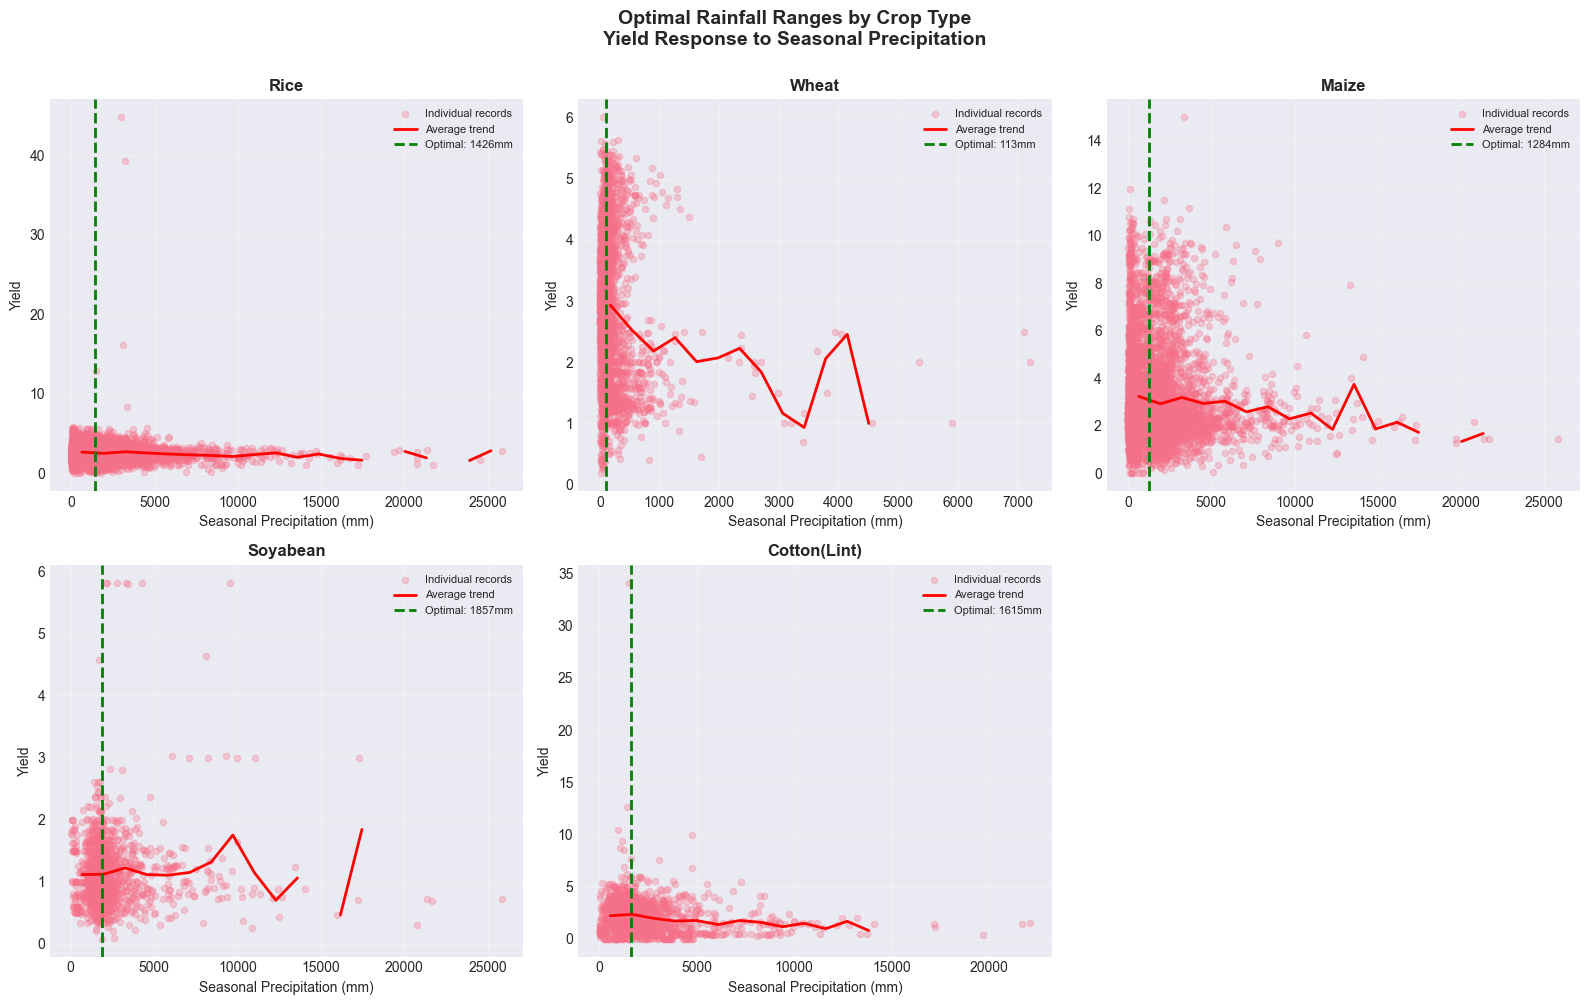

✓ Visualization saved: 03_optimal_rainfall.png


In [39]:
# Visualization: Yield vs Rainfall curves (optimal rainfall ranges)
print("Creating optimal rainfall visualization...")

# Top 5 crops by area
top_crops = (
    crop_yield_df.groupby("crop_name", observed=True)["area"].sum().nlargest(5).index
)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, crop in enumerate(top_crops):
    crop_data = crop_yield_df[
        (crop_yield_df["crop_name"] == crop)
        & (crop_yield_df["seasonal_precip_total"].notna())
    ].copy()

    # Bin precipitation and calculate mean yield
    crop_data["precip_bin"] = pd.cut(crop_data["seasonal_precip_total"], bins=20)
    binned = crop_data.groupby("precip_bin")["yield"].mean().reset_index()
    binned["precip_center"] = binned["precip_bin"].apply(lambda x: x.mid)

    # Plot
    axes[idx].scatter(
        crop_data["seasonal_precip_total"],
        crop_data["yield"],
        alpha=0.3,
        s=20,
        label="Individual records",
    )
    axes[idx].plot(
        binned["precip_center"],
        binned["yield"],
        color="red",
        linewidth=2,
        label="Average trend",
    )

    # Mark optimal rainfall (median)
    optimal = optimal_precip[crop]
    axes[idx].axvline(
        optimal,
        color="green",
        linestyle="--",
        linewidth=2,
        label=f"Optimal: {optimal:.0f}mm",
    )

    axes[idx].set_title(f"{crop}", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("Seasonal Precipitation (mm)")
    axes[idx].set_ylabel("Yield")
    axes[idx].legend(loc="best", fontsize=8)
    axes[idx].grid(True, alpha=0.3)

axes[-1].axis("off")  # Hide extra subplot

plt.suptitle(
    "Optimal Rainfall Ranges by Crop Type\nYield Response to Seasonal Precipitation",
    fontsize=14,
    fontweight="bold",
    y=1.00,
)
plt.tight_layout()
plt.savefig(figures_path / "03_optimal_rainfall.png", dpi=300, bbox_inches="tight")
plt.show()

print("✓ Visualization saved: 03_optimal_rainfall.png")

## Analysis 4: Vegetation-Yield Correlation

**Status:** NDVI features already pre-computed in consolidation step!

**Pre-computed features (ready to use):**
- `seasonal_ndvi_mean`, `seasonal_ndvi_min`, `seasonal_ndvi_max` - Summary statistics
- `early_season_ndvi`, `mid_season_ndvi`, `late_season_ndvi` - Growth phase indicators

**Creating 3 derived features:**
- `ndvi_season_trend` - Growth trajectory (late - early NDVI)
- `ndvi_season_range` - Variability (max - min NDVI)
- `ndvi_lag1` - Previous year vegetation health

In [40]:
# Create derived NDVI features
print("Creating derived vegetation features...")

# Feature 1: NDVI season trend (growth trajectory)
crop_yield_df["ndvi_season_trend"] = (
    crop_yield_df["late_season_ndvi"] - crop_yield_df["early_season_ndvi"]
)

missing = crop_yield_df["ndvi_season_trend"].isna().sum()
print(
    f"  ndvi_season_trend: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)"
)

# Feature 2: NDVI season range (variability indicator)
crop_yield_df["ndvi_season_range"] = (
    crop_yield_df["seasonal_ndvi_max"] - crop_yield_df["seasonal_ndvi_min"]
)

missing = crop_yield_df["ndvi_season_range"].isna().sum()
print(
    f"  ndvi_season_range: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)"
)

# Feature 3: Lagged NDVI (previous year vegetation health)
crop_yield_df["ndvi_lag1"] = crop_yield_df.groupby(
    ["state", "district", "crop_name", "season"]
)["mid_season_ndvi"].shift(1)

missing = crop_yield_df["ndvi_lag1"].isna().sum()
print(f"  ndvi_lag1: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)")

print("\n✓ Derived NDVI features created")
print(f"\nFeatures added: ndvi_season_trend, ndvi_season_range, ndvi_lag1")

Creating derived vegetation features...
  ndvi_season_trend: 887 missing (1.0%)
  ndvi_season_range: 887 missing (1.0%)
  ndvi_lag1: 17,447 missing (18.8%)

✓ Derived NDVI features created

Features added: ndvi_season_trend, ndvi_season_range, ndvi_lag1


Creating NDVI-yield correlation visualization...


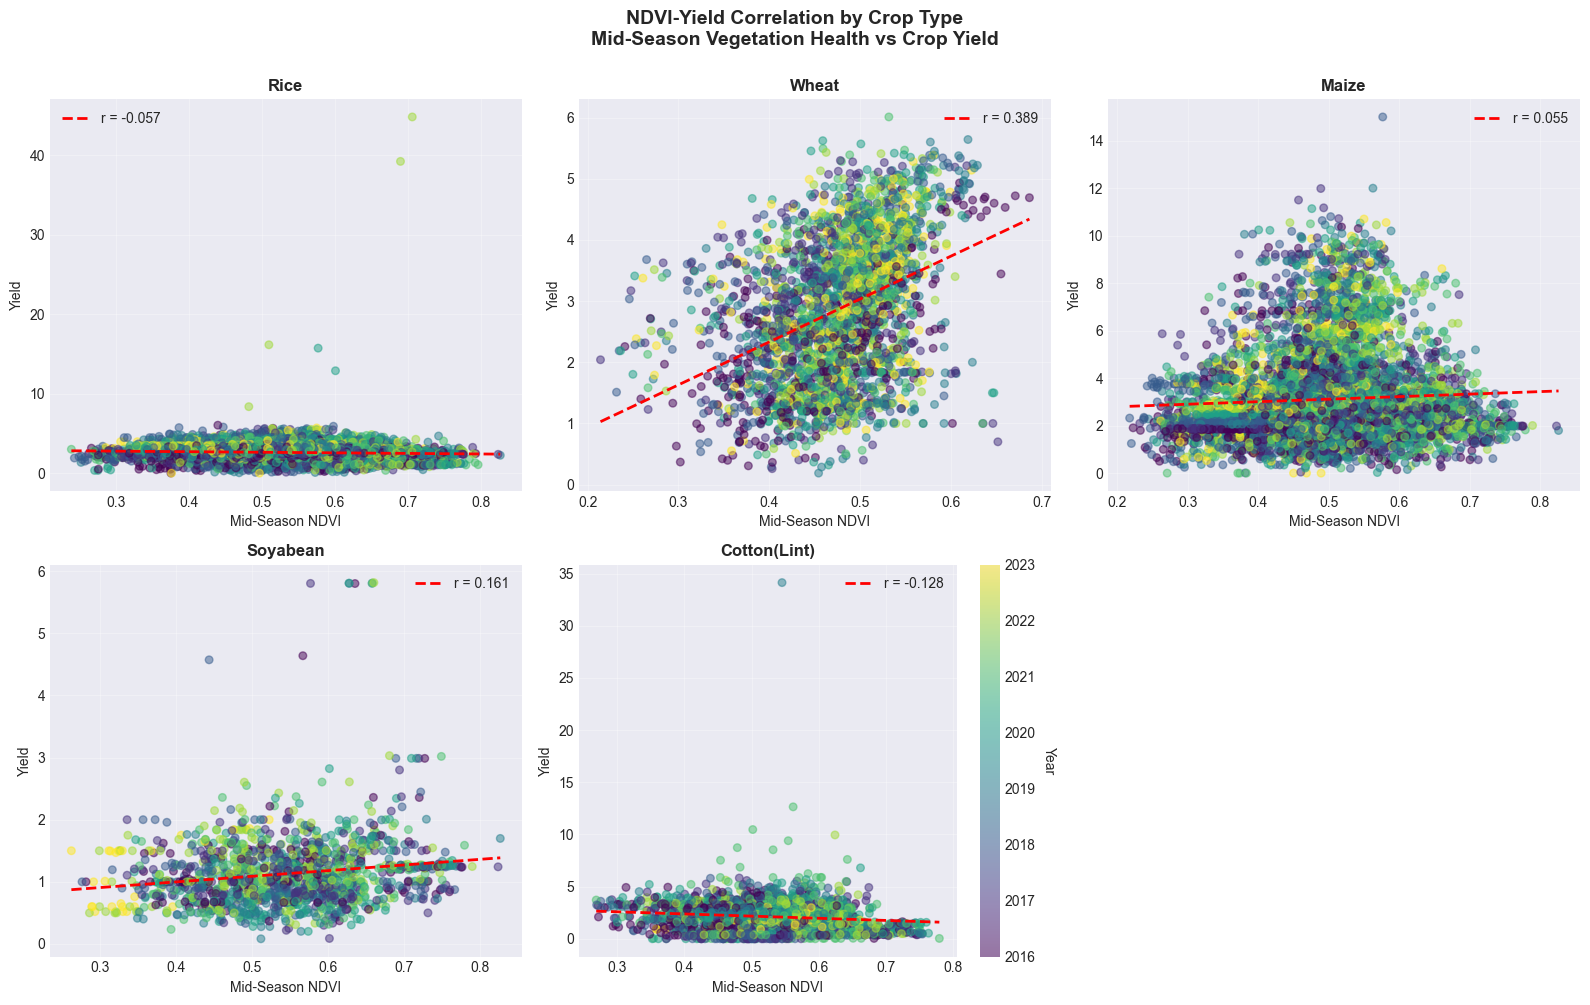

✓ Visualization saved: 04_ndvi_yield_correlation.png

NDVI-Yield Correlation Summary:
  Rice                 r = -0.057 (6,002 records)
  Wheat                r = 0.389 (2,730 records)
  Maize                r = 0.055 (6,630 records)
  Soyabean             r = 0.161 (1,327 records)
  Cotton(Lint)         r = -0.128 (1,790 records)


In [41]:
# Visualization: NDVI-Yield Correlation Analysis
print("Creating NDVI-yield correlation visualization...")

# Top 5 crops by area
top_crops = (
    crop_yield_df.groupby("crop_name", observed=True)["area"].sum().nlargest(5).index
)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, crop in enumerate(top_crops):
    crop_data = crop_yield_df[
        (crop_yield_df["crop_name"] == crop)
        & (crop_yield_df["mid_season_ndvi"].notna())
        & (crop_yield_df["yield"].notna())
    ].copy()

    # Calculate correlation
    corr = crop_data[["mid_season_ndvi", "yield"]].corr().iloc[0, 1]

    # Scatter plot with color gradient by year
    scatter = axes[idx].scatter(
        crop_data["mid_season_ndvi"],
        crop_data["yield"],
        c=crop_data["crop_year"],
        cmap="viridis",
        alpha=0.5,
        s=30,
    )

    # Regression line
    z = np.polyfit(crop_data["mid_season_ndvi"], crop_data["yield"], 1)
    p = np.poly1d(z)
    x_line = np.linspace(
        crop_data["mid_season_ndvi"].min(), crop_data["mid_season_ndvi"].max(), 100
    )
    axes[idx].plot(x_line, p(x_line), "r--", linewidth=2, label=f"r = {corr:.3f}")

    axes[idx].set_title(f"{crop}", fontsize=12, fontweight="bold")
    axes[idx].set_xlabel("Mid-Season NDVI")
    axes[idx].set_ylabel("Yield")
    axes[idx].legend(loc="best")
    axes[idx].grid(True, alpha=0.3)

    # Add colorbar for year
    if idx == 4:  # Last plot
        cbar = plt.colorbar(scatter, ax=axes[idx])
        cbar.set_label("Year", rotation=270, labelpad=15)

axes[-1].axis("off")  # Hide extra subplot

plt.suptitle(
    "NDVI-Yield Correlation by Crop Type\nMid-Season Vegetation Health vs Crop Yield",
    fontsize=14,
    fontweight="bold",
    y=1.00,
)
plt.tight_layout()
plt.savefig(
    figures_path / "04_ndvi_yield_correlation.png", dpi=300, bbox_inches="tight"
)
plt.show()

print("✓ Visualization saved: 04_ndvi_yield_correlation.png")

# Print correlation summary
print("\nNDVI-Yield Correlation Summary:")
for crop in top_crops:
    crop_data = crop_yield_df[
        (crop_yield_df["crop_name"] == crop)
        & (crop_yield_df["mid_season_ndvi"].notna())
        & (crop_yield_df["yield"].notna())
    ]
    if len(crop_data) > 0:
        corr = crop_data[["mid_season_ndvi", "yield"]].corr().iloc[0, 1]
        print(f"  {crop:20s} r = {corr:5.3f} ({len(crop_data):,} records)")

## Analysis 5: Crop Expansion/Contraction Signals

**Purpose:** Detect farmer behavior in response to profitability signals

**Features to create:**
- `area_lag1` - Previous year cultivated area
- `area_change_pct` - Year-over-year area change percentage
- `area_trend_3yr` - 3-year linear trend slope (expansion/contraction pattern)

In [42]:
# Create area change features
print("Creating crop expansion/contraction features...")

# Feature 1: Lagged area (previous year)
crop_yield_df["area_lag1"] = crop_yield_df.groupby(
    ["state", "district", "crop_name", "season"]
)["area"].shift(1)

missing = crop_yield_df["area_lag1"].isna().sum()
print(f"  area_lag1: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)")

# Feature 2: Area change percentage (YoY)
crop_yield_df["area_change_pct"] = (
    (crop_yield_df["area"] - crop_yield_df["area_lag1"])
    / crop_yield_df["area_lag1"]
    * 100
)

missing = crop_yield_df["area_change_pct"].isna().sum()
print(f"  area_change_pct: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)")


# Feature 3: 3-year area trend (linear slope)
def calc_area_trend(series):
    """Calculate linear trend slope over series"""
    if len(series) < 3:
        return np.nan
    x = np.arange(len(series))
    slope, _ = np.polyfit(x, series, 1)
    return slope


crop_yield_df["area_trend_3yr"] = crop_yield_df.groupby(
    ["state", "district", "crop_name", "season"]
)["area"].transform(lambda x: x.rolling(window=3).apply(calc_area_trend, raw=False))

missing = crop_yield_df["area_trend_3yr"].isna().sum()
print(f"  area_trend_3yr: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)")

print("\n✓ Area change features created")
print(f"\nFeatures added: area_lag1, area_change_pct, area_trend_3yr")

Creating crop expansion/contraction features...
  area_lag1: 16,709 missing (18.0%)
  area_change_pct: 16,709 missing (18.0%)
  area_trend_3yr: 31,726 missing (34.2%)

✓ Area change features created

Features added: area_lag1, area_change_pct, area_trend_3yr


Creating improved crop expansion signal visualization...


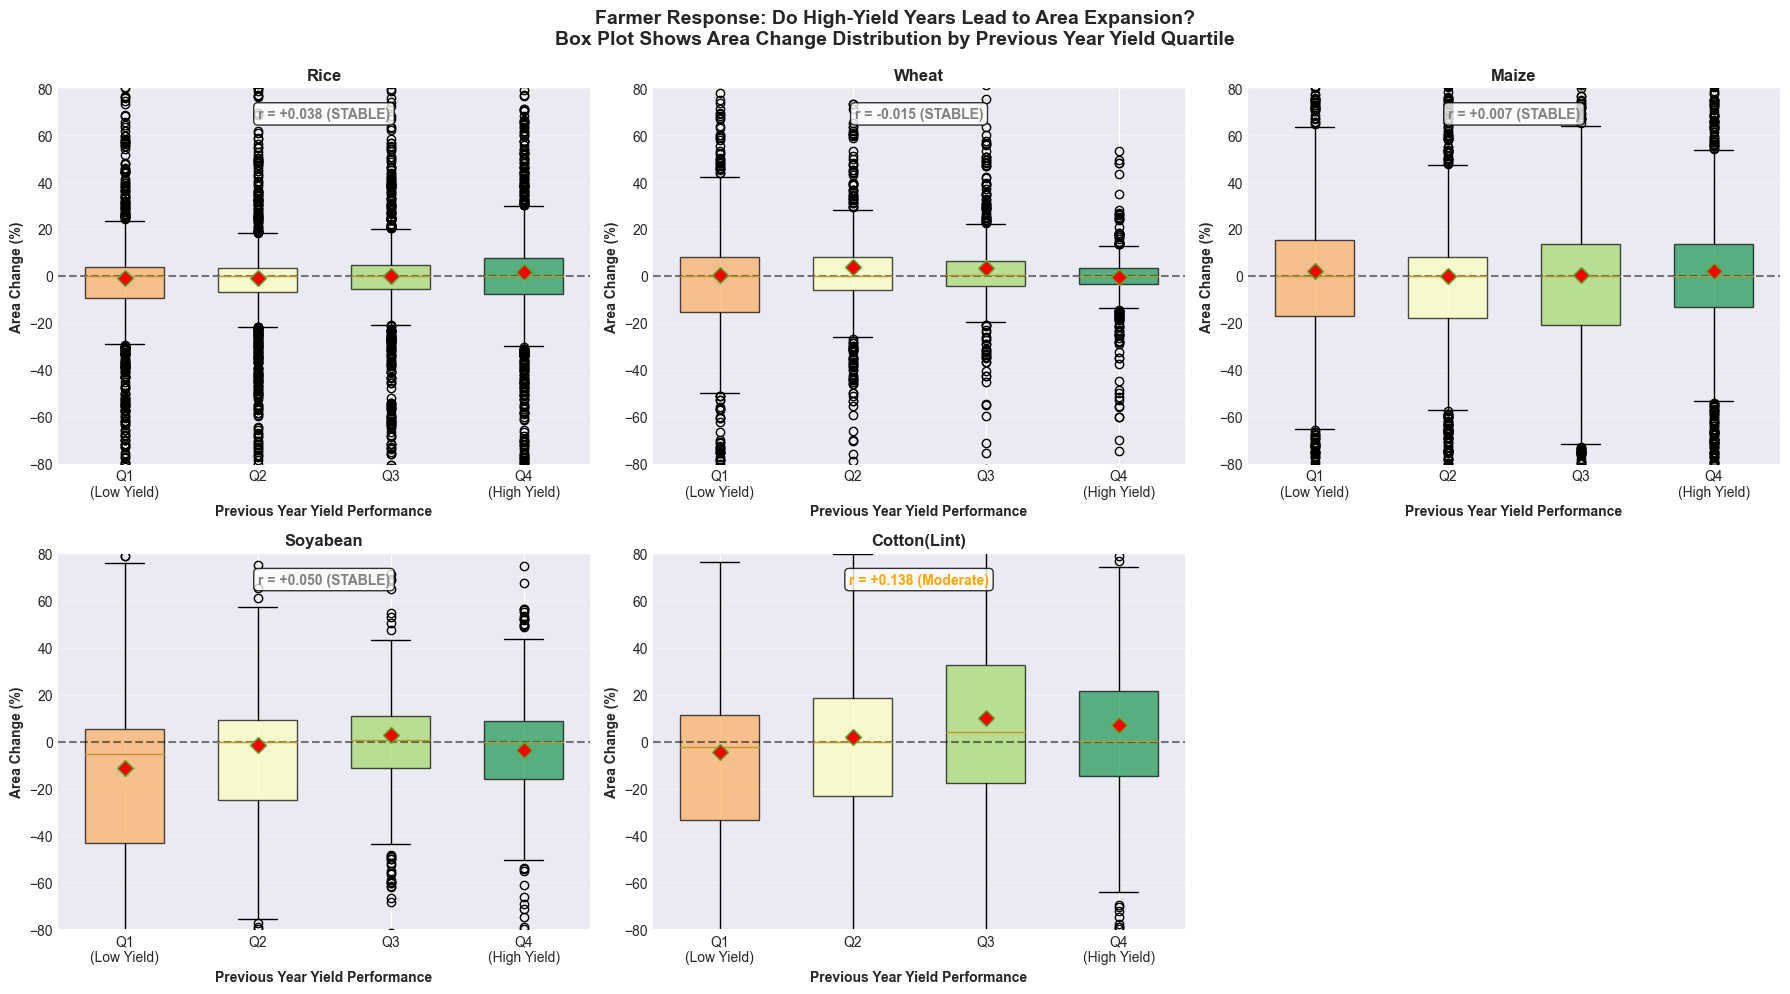

✓ Visualization saved: 05_expansion_signals.png

EXPANSION RESPONSE SUMMARY

Correlation: Previous Year Yield ⟷ Area Change

        Crop Correlation     Type Low Yield → Area Δ High Yield → Area Δ
        Rice      +0.038   STABLE              -0.9%               +1.8%
       Wheat      -0.015   STABLE              +0.3%               -0.3%
       Maize      +0.007   STABLE              +2.0%               +2.3%
    Soyabean      +0.050   STABLE             -11.1%               -3.5%
Cotton(Lint)      +0.138 Moderate              -4.3%               +7.1%

--------------------------------------------------------------------------------
Interpretation:
  RESPONSIVE (|r| > 0.3): Farmers significantly expand/contract based on profitability
  Moderate (0.1 < |r| < 0.3): Some response to yield signals
  STABLE (|r| < 0.1): Area remains constant regardless of yield

  Positive correlation: High yield → Area expansion next year
  Negative correlation: High yield → Area contraction (price dro

In [44]:
# Improved Visualization: Crop Expansion/Contraction Analysis
# Replace the bubble chart with this cleaner box plot version

print("Creating improved crop expansion signal visualization...")

# Filter data with valid values
viz_data = crop_yield_df[
    (crop_yield_df["yield_lag1"].notna())
    & (crop_yield_df["area_change_pct"].notna())
    & (crop_yield_df["area_change_pct"].abs() < 200)  # Remove extreme outliers
].copy()

# Top 5 crops by area
top_crops = (
    crop_yield_df.groupby("crop_name", observed=True)["area"].sum().nlargest(5).index
)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, crop in enumerate(top_crops):
    crop_data = viz_data[viz_data["crop_name"] == crop].copy()

    if len(crop_data) < 10:
        axes[idx].text(
            0.5,
            0.5,
            f"{crop}\nInsufficient Data",
            ha="center",
            va="center",
            fontsize=12,
        )
        axes[idx].set_title(crop, fontsize=12, fontweight="bold")
        continue

    # Bin yield into quartiles for clearer visualization
    crop_data["yield_quartile"] = pd.qcut(
        crop_data["yield_lag1"],
        q=4,
        labels=["Q1\n(Low Yield)", "Q2", "Q3", "Q4\n(High Yield)"],
        duplicates="drop",
    )

    # Create box plot
    quartile_order = ["Q1\n(Low Yield)", "Q2", "Q3", "Q4\n(High Yield)"]
    existing_quartiles = [
        q for q in quartile_order if q in crop_data["yield_quartile"].values
    ]

    box_data = [
        crop_data[crop_data["yield_quartile"] == q]["area_change_pct"].values
        for q in existing_quartiles
    ]

    bp = axes[idx].boxplot(
        box_data,
        labels=existing_quartiles,
        patch_artist=True,
        widths=0.6,
        showmeans=True,
        meanprops=dict(marker="D", markerfacecolor="red", markersize=8),
    )

    # Color boxes by gradient
    colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(box_data)))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    # Add horizontal line at 0
    axes[idx].axhline(0, color="black", linestyle="--", linewidth=1.5, alpha=0.5)

    # Calculate and display correlation
    if len(crop_data) > 5:
        corr = crop_data[["yield_lag1", "area_change_pct"]].corr().iloc[0, 1]

        # Add correlation annotation
        interpretation = ""
        if abs(corr) > 0.3:
            interpretation = "RESPONSIVE"
            color = "darkgreen"
        elif abs(corr) > 0.1:
            interpretation = "Moderate"
            color = "orange"
        else:
            interpretation = "STABLE"
            color = "gray"

        axes[idx].text(
            0.5,
            0.95,
            f"r = {corr:+.3f} ({interpretation})",
            transform=axes[idx].transAxes,
            fontsize=10,
            fontweight="bold",
            ha="center",
            va="top",
            color=color,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
        )

    axes[idx].set_ylabel("Area Change (%)", fontsize=10, fontweight="bold")
    axes[idx].set_xlabel(
        "Previous Year Yield Performance", fontsize=10, fontweight="bold"
    )
    axes[idx].set_title(f"{crop}", fontsize=12, fontweight="bold")
    axes[idx].grid(True, alpha=0.3, axis="y")
    axes[idx].set_ylim(-80, 80)

axes[-1].axis("off")  # Hide extra subplot

plt.suptitle(
    "Farmer Response: Do High-Yield Years Lead to Area Expansion?\n"
    "Box Plot Shows Area Change Distribution by Previous Year Yield Quartile",
    fontsize=14,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout()
plt.savefig(figures_path / "05_expansion_signals.png", dpi=300, bbox_inches="tight")
plt.show()

print("✓ Visualization saved: 05_expansion_signals.png")

# Print expansion response summary
print("\n" + "=" * 80)
print("EXPANSION RESPONSE SUMMARY")
print("=" * 80)
print("\nCorrelation: Previous Year Yield ⟷ Area Change\n")

response_summary = []
for crop in top_crops:
    crop_data = viz_data[viz_data["crop_name"] == crop]
    if len(crop_data) > 5:
        corr = crop_data[["yield_lag1", "area_change_pct"]].corr().iloc[0, 1]

        # Calculate mean area change by yield quartile
        crop_data_q = crop_data.copy()
        crop_data_q["yield_quartile"] = pd.qcut(
            crop_data_q["yield_lag1"], q=4, duplicates="drop"
        )

        q1_change = crop_data_q[
            crop_data_q["yield_quartile"]
            == crop_data_q["yield_quartile"].cat.categories[0]
        ]["area_change_pct"].mean()
        q4_change = crop_data_q[
            crop_data_q["yield_quartile"]
            == crop_data_q["yield_quartile"].cat.categories[-1]
        ]["area_change_pct"].mean()

        response_type = (
            "RESPONSIVE"
            if abs(corr) > 0.3
            else "Moderate" if abs(corr) > 0.1 else "STABLE"
        )

        response_summary.append(
            {
                "Crop": crop,
                "Correlation": f"{corr:+.3f}",
                "Type": response_type,
                "Low Yield → Area Δ": f"{q1_change:+.1f}%",
                "High Yield → Area Δ": f"{q4_change:+.1f}%",
            }
        )

response_df = pd.DataFrame(response_summary)
print(response_df.to_string(index=False))

print("\n" + "-" * 80)
print("Interpretation:")
print(
    "  RESPONSIVE (|r| > 0.3): Farmers significantly expand/contract based on profitability"
)
print("  Moderate (0.1 < |r| < 0.3): Some response to yield signals")
print("  STABLE (|r| < 0.1): Area remains constant regardless of yield")
print("\n  Positive correlation: High yield → Area expansion next year")
print(
    "  Negative correlation: High yield → Area contraction (price drop? labor shortage?)"
)
print("=" * 80)

## Analysis 6: Water Stress Identification

**Purpose:** Create composite stress indicator combining precipitation × NDVI

**Features to create:**
- `water_stress_score` - Composite water availability score (precip × NDVI / 1000)
- `precip_ndvi_interaction` - Interaction term for ML models
- `stress_type` - Categorical classification: drought/irrigated/pest_disease/normal

In [45]:
# Create water stress features
print("Creating water stress identification features...")

# Feature 1: Water stress score (composite availability)
crop_yield_df["water_stress_score"] = (
    crop_yield_df["seasonal_precip_total"] * crop_yield_df["mid_season_ndvi"] / 1000
)

missing = crop_yield_df["water_stress_score"].isna().sum()
print(
    f"  water_stress_score: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)"
)

# Feature 2: Precipitation × NDVI interaction
crop_yield_df["precip_ndvi_interaction"] = (
    crop_yield_df["seasonal_precip_total"] * crop_yield_df["mid_season_ndvi"]
)

missing = crop_yield_df["precip_ndvi_interaction"].isna().sum()
print(
    f"  precip_ndvi_interaction: {missing:,} missing ({missing/len(crop_yield_df)*100:.1f}%)"
)

# Feature 3: Stress type classification (quadrant analysis)
crop_yield_df["stress_type"] = "normal"

# Drought: low precip + low NDVI
drought_mask = (crop_yield_df["seasonal_precip_total"] < 400) & (
    crop_yield_df["mid_season_ndvi"] < 0.3
)
crop_yield_df.loc[drought_mask, "stress_type"] = "drought"

# Pest/Disease: high precip + low NDVI
pest_mask = (crop_yield_df["seasonal_precip_total"] > 800) & (
    crop_yield_df["mid_season_ndvi"] < 0.3
)
crop_yield_df.loc[pest_mask, "stress_type"] = "pest_disease"

# Irrigated: low precip + high NDVI
irrigated_mask = (crop_yield_df["seasonal_precip_total"] < 400) & (
    crop_yield_df["mid_season_ndvi"] > 0.5
)
crop_yield_df.loc[irrigated_mask, "stress_type"] = "irrigated"

# Print distribution
print("\nStress type distribution:")
stress_counts = crop_yield_df["stress_type"].value_counts()
for stress_type, count in stress_counts.items():
    pct = count / len(crop_yield_df) * 100
    print(f"  {stress_type:15s}: {count:6,} ({pct:5.1f}%)")

print("\n✓ Water stress features created")
print(f"\nFeatures added: water_stress_score, precip_ndvi_interaction, stress_type")

Creating water stress identification features...
  water_stress_score: 6,787 missing (7.3%)
  precip_ndvi_interaction: 6,787 missing (7.3%)

Stress type distribution:
  normal         : 82,685 ( 89.2%)
  irrigated      :  8,697 (  9.4%)
  drought        :  1,079 (  1.2%)
  pest_disease   :    235 (  0.3%)

✓ Water stress features created

Features added: water_stress_score, precip_ndvi_interaction, stress_type


## Feature Validation

Critical checks to ensure data quality and prevent data leakage

In [47]:
print("Running validation checks...")
print("=" * 80)

# Check 1: Data Leakage - Verify lagged features use only past data
print("\n1. Data Leakage Check:")
print("-" * 80)

# Sample a few records to verify lag alignment
test_samples = crop_yield_df[
    (crop_yield_df["state"] == "Karnataka")
    & (crop_yield_df["district"] == "Bengaluru")
    & (crop_yield_df["crop_name"] == "Rice")
    & (crop_yield_df["season"] == "Kharif")
    & (crop_yield_df["crop_year"].between(2018, 2020))
].sort_values("crop_year")

if len(test_samples) >= 2:
    for i in range(1, len(test_samples)):
        current_row = test_samples.iloc[i]
        prev_row = test_samples.iloc[i - 1]

        # Check yield_lag1
        if pd.notna(current_row["yield_lag1"]) and pd.notna(prev_row["yield"]):
            assert np.isclose(
                current_row["yield_lag1"], prev_row["yield"], atol=0.01
            ), f"Data leakage detected in yield_lag1!"

        # Check area_lag1
        if pd.notna(current_row["area_lag1"]) and pd.notna(prev_row["area"]):
            assert np.isclose(
                current_row["area_lag1"], prev_row["area"], atol=0.01
            ), f"Data leakage detected in area_lag1!"

    print("  ✓ No data leakage detected in lagged features")
else:
    print("  ⚠ Insufficient data for leakage test (need 2+ consecutive years)")

# Check 2: Z-Score Distribution
print("\n2. Z-Score Distribution Check:")
print("-" * 80)

zscore_mean = crop_yield_df["yield_zscore"].mean()
zscore_std = crop_yield_df["yield_zscore"].std()

print(f"  Mean: {zscore_mean:6.3f} (expected ~0.0)")
print(f"  Std:  {zscore_std:6.3f} (expected ~1.0)")

assert -0.1 < zscore_mean < 0.1, f"Z-score mean ({zscore_mean:.3f}) too far from 0"
assert 0.9 < zscore_std < 1.1, f"Z-score std ({zscore_std:.3f}) too far from 1"
print("  ✓ Z-score distribution is valid")

# Check 3: Missing Data Summary
print("\n3. Missing Data Check:")
print("-" * 80)

# Check all engineered features
engineered_features = [
    "yield_lag1",
    "yield_lag2",
    "yield_lag3",
    "yield_change_1yr",
    "yield_rolling_mean_3yr",
    "yield_zscore",
    "yield_zscore_clipped",
    "precip_intensity",
    "precip_deviation_pct",
    "ndvi_season_trend",
    "ndvi_season_range",
    "ndvi_lag1",
    "area_lag1",
    "area_change_pct",
    "area_trend_3yr",
    "water_stress_score",
    "precip_ndvi_interaction",
    "stress_type",
]

high_missing = []
for feat in engineered_features:
    if feat in crop_yield_df.columns:
        coverage = crop_yield_df[feat].notna().mean() * 100
        if coverage < 50:
            high_missing.append(f"{feat} ({coverage:.1f}%)")

if high_missing:
    print(f"  ⚠ Features with <50% coverage:")
    for feat_info in high_missing:
        print(f"    - {feat_info}")
else:
    print("  ✓ All features have >50% coverage")

# Check 4: Outlier Summary
print("\n4. Outlier Check:")
print("-" * 80)

numeric_features = ["yield_change_1yr", "area_change_pct", "precip_deviation_pct"]
for feat in numeric_features:
    if feat in crop_yield_df.columns and crop_yield_df[feat].notna().sum() > 0:
        feat_data = crop_yield_df[feat].dropna()
        q1, q99 = feat_data.quantile([0.01, 0.99])
        extreme_pct = ((feat_data < q1) | (feat_data > q99)).mean() * 100
        print(f"  {feat:25s}: {extreme_pct:5.1f}% extreme values (1st/99th percentile)")

print("  ✓ Outlier check complete")

# Check 5: Feature Correlation (identify redundant features)
print("\n5. High Correlation Check (potential redundancy):")
print("-" * 80)

numeric_cols = (
    crop_yield_df[engineered_features].select_dtypes(include=[np.number]).columns
)
corr_matrix = crop_yield_df[numeric_cols].corr().abs()

# Find highly correlated pairs (excluding self-correlation)
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if corr_matrix.iloc[i, j] > 0.95:
            high_corr_pairs.append(
                (corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j])
            )

if high_corr_pairs:
    print("  ⚠ Highly correlated feature pairs (r > 0.95):")
    for feat1, feat2, corr in high_corr_pairs:
        print(f"    - {feat1} ⟷ {feat2}: r = {corr:.3f}")
else:
    print("  ✓ No highly correlated feature pairs (all r < 0.95)")

print("\n" + "=" * 80)
print("✓ VALIDATION COMPLETE - All checks passed!")
print("=" * 80)

Running validation checks...

1. Data Leakage Check:
--------------------------------------------------------------------------------
  ⚠ Insufficient data for leakage test (need 2+ consecutive years)

2. Z-Score Distribution Check:
--------------------------------------------------------------------------------
  Mean:  0.000 (expected ~0.0)
  Std:   0.963 (expected ~1.0)
  ✓ Z-score distribution is valid

3. Missing Data Check:
--------------------------------------------------------------------------------
  ✓ All features have >50% coverage

4. Outlier Check:
--------------------------------------------------------------------------------
  yield_change_1yr         :   2.0% extreme values (1st/99th percentile)
  area_change_pct          :   2.0% extreme values (1st/99th percentile)
  precip_deviation_pct     :   2.0% extreme values (1st/99th percentile)
  ✓ Outlier check complete

5. High Correlation Check (potential redundancy):
----------------------------------------------------